# Testing the computational claim

Level 4. Prerequisites: all three preceding lessons and a completed frozen experimental export. Reading time: 40 minutes.

**Question:** Does the asymmetric projection's smaller original formulation meet the registered end-to-end improvement criterion against the faster matched baseline on held-out inputs?


## Objectives

A computational proposal must survive a comparison that could reject it. The candidate changes the side-specific interval proximal operation while keeping the principal OSQP system in the original variable dimension. That structural observation motivates an engineering hypothesis; it is not evidence that a wall-clock endpoint improves. Validation cost, dense preparation, iteration counts and backend maturity may overturn an argument based only on matrix size.

We will run the methods on a development problem, inspect their original KKT relations, examine a conditioning change and recompute the frozen held-out endpoint. The held-out seeds were registered before generation. This notebook does not choose a favorable subset or retune the candidate after viewing results. Its conclusion will distinguish a bounded implementation measurement from mathematical novelty, practitioner adoption and release acceptance.


## Setup

Use a separate Python 3.12 environment. The native engine is a separate distribution. Install the exact environment outside the notebook:

```bash
pip install "softqp==0.1.0"
pip install "numpy==2.5.4"
pip install "scipy==1.18.1"
pip install "matplotlib==3.11.2"
pip install "osqp==1.1.3"
pip install "daqp==0.10.3"
pip install "elastiqp==0.2.0"
```

The single setup cell resolves the repository, imports the methods and prints numerical versions. No installation runs inside a kernel.


In [1]:
# Resolve inputs once so every scientific cell focuses on the optimization.
from pathlib import Path
import sys
import json
import importlib.metadata
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from softqp.solvers import solve
from softqp.flex import solve_flex
from softqp.elasti import solve_elastiqp
from softqp.sessions import PreparedSolver
candidates = [Path.cwd(), *Path.cwd().parents]
root = next(p for p in candidates if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from pipeline.softqp_cases import scalar, mpc
from pipeline.softqp_campaign import generated_problem, primary_endpoint
from pipeline.optimality import kkt
from pipeline.control import predict_states
for distribution in ("softqp", "numpy", "scipy", "matplotlib", "osqp", "daqp", "elastiqp"):
    print(distribution, importlib.metadata.version(distribution))
accurate = dict(eps_abs=1e-9, eps_rel=1e-9, adaptive_rho_interval=25)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})


softqp 0.1.0
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
osqp 1.1.3
daqp 0.10.3
elastiqp 0.2.0


## Data

The executable development example uses seed 1000, n=32, density 0.05, condition one and asymmetric elastic costs. The registered campaign separately spans six held-out seeds, n=32/64/128/256, two densities, two diagonal conditions and three penalty families. Seven measured repetitions follow a warm-up for each backend and instance. Method order is randomized within each paired repetition.

Read the complete raw JSONL observations once. Warm-ups, incompatibilities, failures and resource limits remain present. The endpoint function applies its registered filter; the notebook does not discard rows before handing them to that function. The source inventory and artifact hashes are checked by the product's export verifier, independently of this lesson.


In [2]:
# Retain the complete denominator before applying the registered endpoint.
campaign = json.loads((root / "data/derived/experiments/campaign.json").read_text(encoding="utf-8"))
trial_file = root / "data/derived/experiments/trials.jsonl"
trials = [json.loads(line) for line in trial_file.read_text(encoding="utf-8").splitlines()]
protocol = campaign["protocol"]
print("Held-out seeds:", protocol["seeds"]["heldout"])
print("Raw observations including warm-ups:", len(trials))


Held-out seeds: [9000, 9001, 9002, 9003, 9004, 9005]
Raw observations including warm-ups: 21888


## Method

Begin with an actual solve at development scale. The extension supports nonnegative side-specific linear/quadratic prices and a fixed hard mask. Its asymmetric scalar proximal update follows convex interval-penalty minimization. The ordinary ADMM system still couples the variables, so rowwise shrinkage does not mean the entire QP decomposes into independent scalar decisions. Adaptive numerical rho can still trigger refactorization; preserving matrix dimensions is not a promise of one factorization forever.

Use equal absolute and relative tolerances for the following matched calls. These educational solves inspect correctness; their fresh wall times are deliberately not used to replace the preregistered campaign measurements.


In [3]:
# This development instance is separate from every held-out evaluation seed.
spec = dict(n=32, density=0.05, seed=1000, family="asymmetric-elastic", condition=1)
problem = generated_problem(spec)
settings = dict(eps_abs=1e-8, eps_rel=1e-8, max_iter=200000)
native_settings = dict(settings, adaptive_rho_interval=25)
candidate = solve(problem, "asymmetric", **native_settings)
print("Candidate dimensions:", candidate["dimensions"])
print(f"Development objective: {candidate['metrics']['objective']:.8f}")


Candidate dimensions: {'variables': 32, 'rows': 64, 'nnz': 144}
Development objective: -84.75011385


A fair lifting comparator must use the compact formulation whenever symmetry permits it. This asymmetric example instead requires distinct finite-side slacks. The high-accuracy independent oracle uses stock OSQP, while the timed campaign's ordinary lift uses the same native fork as the candidate. That separation avoids confusing an implementation difference between two OSQP builds with a formulation advantage.


In [4]:
# Use an independent stock implementation for this correctness oracle.
lifted = solve(problem, "lifted", reference_backend="stock", **native_settings)
relative_gap = abs(candidate["metrics"]["objective"] - lifted["metrics"]["objective"])
relative_gap /= max(1.0, abs(lifted["metrics"]["objective"]))
reduction = 1 - candidate["dimensions"]["variables"] / lifted["dimensions"]["variables"]
print("Lifted dimensions:", lifted["dimensions"])
print(f"Primal-dimension reduction: {100 * reduction:.6f}%")
print(f"Normalized development objective gap: {relative_gap:.3e}")


Lifted dimensions: {'variables': 136, 'rows': 220, 'nnz': 547}
Primal-dimension reduction: 76.470588%
Normalized development objective gap: 4.599e-10


DAQP is a necessary comparator because side-specific soft costs already exist in its interface. The candidate cannot claim a new modeling capability merely because it supports unequal prices. The registered endpoint therefore compares against the faster paired observation from DAQP and native lifting, not whichever baseline happens to look slowest. Run DAQP now to inspect that same scientific objective on another algorithm.


In [5]:
# A pre-existing side-specific algorithm prevents a novelty claim based only on asymmetry.
daqp = solve(problem, "daqp", **native_settings)
print("DAQP dimensions:", daqp["dimensions"])
print(f"DAQP objective difference: {abs(daqp['metrics']['objective'] - lifted['metrics']['objective']):.3e}")


DAQP dimensions: {'variables': 32, 'rows': 64, 'nnz': 144}
DAQP objective difference: 3.492e-09


Audit the recovered primal and dual vectors, not only costs. For a convex problem, stationarity and membership in the interval-penalty subgradient, together with hard feasibility, characterize optimality under the applicable assumptions. The proximal fixed-point defect tests the subgradient relation at kinks without choosing an arbitrary derivative. This makes a false stationary point easier to detect than an objective comparison alone.


In [6]:
# The dual must match the declared penalty, not merely cancel a gradient.
for result in [candidate, lifted, daqp]:
    audit = kkt(problem, result["x"], result["y"])
    print(result["method"], f"stationarity {audit['normalized_stationarity']:.3e}",
          f"proximal {audit['normalized_proximal_defect']:.3e}",
          f"hard {audit['hard_violation']:.3e}")


asymmetric stationarity 8.255e-10 proximal 9.106e-09 hard 6.574e-10
lifted stationarity 6.609e-10 proximal 5.637e-10 hard 3.051e-11
daqp stationarity 9.720e-17 proximal 1.887e-15 hard 1.554e-15


## Comparison

Plot the representation sizes only after establishing matched semantics. DAQP also works without the ordinary lift's explicit slack expansion. Consequently, a candidate-size advantage relative to lifting says nothing by itself about superiority to the stronger baseline. This is why the primary endpoint uses the faster of both references for every paired observation.


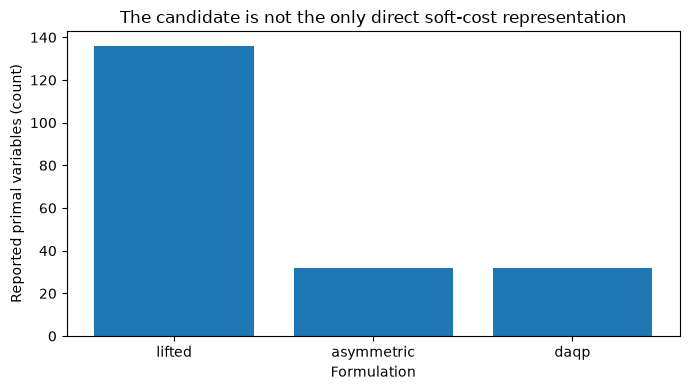

In [7]:
# Report mathematical dimensions without translating them into invented factor times.
results = [lifted, candidate, daqp]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([r["method"] for r in results], [r["dimensions"]["variables"] for r in results])
ax.set(xlabel="Formulation", ylabel="Reported primal variables (count)",
       title="The candidate is not the only direct soft-cost representation")
fig.tight_layout()
plt.show()


The ordinary lift has more explicit primal variables because it represents each priced side through auxiliary quantities. Both direct methods avoid that particular expansion. Their bars do not expose iteration work, numerical conditioning, Python validation overhead or active-set preparation. The figure therefore motivates a computational test rather than answering it, and it prevents a comparison that awards the candidate a unique capability already present in a published baseline.


Increase only the diagonal Hessian condition on the development example. The generator keeps rows, targets, bounds and prices fixed within this seed. A successful objective check at condition one cannot guarantee behavior at a million, especially when scaling interacts with stopping tolerances. This call illustrates the controlled question; the full robustness sweep has its own retained failure counts and does not disappear into the primary timing statistic.


In [8]:
# Preserve A, q and prices while challenging the objective's conditioning.
difficult = generated_problem(dict(spec, condition=1000000))
difficult_native = solve(difficult, "asymmetric", **native_settings)
difficult_lift = solve(difficult, "lifted", **native_settings)
condition_gap = abs(difficult_native["metrics"]["objective"] - difficult_lift["metrics"]["objective"])
print(f"Condition-one-million objective difference: {condition_gap:.3e}")
print(f"Condition-one-million hard error: {difficult_native['metrics']['hard_violation']:.3e}")


Condition-one-million objective difference: 1.880e-08
Condition-one-million hard error: 1.110e-16


## Evidence

The primary population is asymmetric elastic, n at least 128 and density 0.05. For each instance and repetition, reduction equals one minus candidate time divided by the faster matched baseline time. Negative values mean slower execution. The registered criterion requires at least 10% median reduction, a two-sided 95% seed-cluster bootstrap interval whose lower endpoint exceeds zero, and no failed compared pair. Whole seed clusters, rather than individual repetitions treated as independent experiments, are resampled.

Recompute that endpoint through the product's analysis method using every raw record. Missing or rejected pairs remain in its denominator. Import time, generation and export are outside the timed call; validation, formulation, setup, solve and original-space evaluation are inside. Isolated factorization time is not instrumented and cannot be reconstructed by subtracting unrelated timers.


In [9]:
# Recompute the registered statistic rather than selecting a favorable chart subset.
endpoint = primary_endpoint(trials, protocol)
print("Registered criterion:", endpoint["state"])
print("Accepted pairs / rejected pairs:", endpoint["paired_samples"], endpoint["rejected_pairs"])
print("Seed clusters:", endpoint["seed_clusters"])
if endpoint["median_relative_reduction"] is None:
    raise ValueError("Complete held-out experimental evidence is required")
print(f"Median relative reduction: {100 * endpoint['median_relative_reduction']:.3f}%")
print("95% interval (%):", [round(100 * x, 3) for x in endpoint["confidence_interval_95"]])


Registered criterion: not-established
Accepted pairs / rejected pairs: 168 0
Seed clusters: 6
Median relative reduction: 0.500%
95% interval (%): [-3.292, 3.945]


Display the registered effect and its seed-cluster interval with both the zero line and the practical target. Crossing zero means the direction is uncertain under this resampling scheme; failing to reach the 10% target is distinct from that uncertainty. A positive point estimate alone is insufficient. The visual also carries the sign convention explicitly so that a slower candidate cannot be presented as an improvement by reversing an axis.


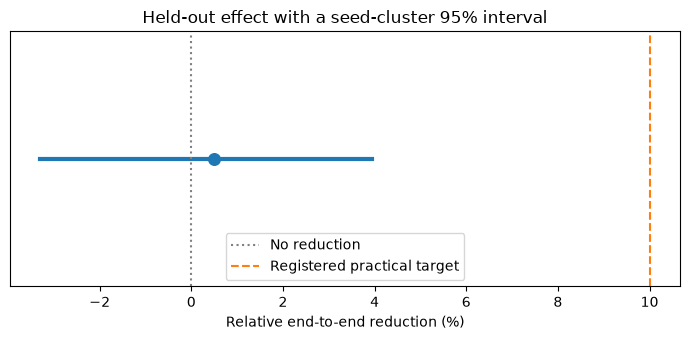

In [10]:
# The interval is descriptive of six seed clusters in this registered implementation regime.
estimate = 100 * endpoint["median_relative_reduction"]
low, high = [100 * x for x in endpoint["confidence_interval_95"]]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([low, high], [0, 0], linewidth=3)
ax.scatter([estimate], [0], s=70)
ax.axvline(0, color="gray", linestyle=":", label="No reduction")
ax.axvline(10, color="C1", linestyle="--", label="Registered practical target")
ax.set(xlabel="Relative end-to-end reduction (%)", yticks=[],
       title="Held-out effect with a seed-cluster 95% interval")
ax.legend()
fig.tight_layout()
plt.show()


This interval reflects repeated paired observations and variation across the registered seed clusters on one numerical environment. It does not cover every control model, machine, Hessian or implementation. The best-baseline comparison and the practical threshold were chosen before held-out generation, so their outcome remains meaningful even if it is unfavorable. Global algorithmic novelty, independent mathematical review and deployed-product acceptance are separate conclusions that this interval cannot establish.


## Results

**Answer:** The candidate does not meet the registered criterion: median relative reduction 0.500%, 95% seed-cluster interval [-3.292%, 3.945%], 168 accepted pairs and 0 rejected pairs. This is a bounded implementation outcome, not proof of global novelty or operational safety.

In the executed development example, the candidate uses 32 variables versus 136 for explicit lifting, a 76.470588% reduction in reported primal dimension. DAQP's direct soft-cost representation shows why that count alone is not a comparative research result. The conclusion above uses the registered wall-clock scope and retains numerical acceptance, not the appearance of a favorable matrix-size plot.


## Summary

Separate a derivation, an implementation property and an empirical improvement. The proximal formula can be correct even when an endpoint fails, and an endpoint can improve without establishing a new mathematical idea. Preserve negative outcomes, narrow any successful claim to its measured regime and seek independent review before scientific promotion. A practitioner deciding whether to adopt the engine still needs representative workloads, platform validation and a justified hard/soft policy.


## References

- [Generalized slack projections](https://arxiv.org/abs/2610.35631).
- [DAQP side-specific soft constraints](https://darnstrom.github.io/daqp/start/advanced/soft).
- [OSQP solver and stopping conditions](https://osqp.org/docs/solver/).
- Frozen protocol: `docs/design/experiments-v1.json`; complete original observations and campaign manifest under `data/derived/experiments/`.
